# 14. Springs and Things

*Physical Modeling in MATLAB* by Allen B. Downey. Run each code cell in order with Shift+Enter; you can change the code and run it again.

The computational tools you have learned so far make up a versatile toolkit for modeling physical systems described by first- and second-order differential equations and systems of equations.

With `ode45` you can compute the state variables of these systems as they change over time. By varying the parameters of the model, you can see what effect they have on the results. Then you can use `fminsearch` and `fzero` to find minimums, maximums, and places where the outputs pass through zero.

These tools are all you need to solve a lot of problems, so this chapter doesn’t present new computational tools (whew!). Instead, we’ll look at some different physical systems and some forces we haven’t dealt with yet, including spring forces and universal gravitation.

The examples in this chapter are a little more open-ended than the previous ones. I will present a motivating problem and some background information, and you will have a chance to implement the models as exercises.

## Bungee Jumping

Suppose you want to set the world record for the highest “bungee dunk,” which is a stunt in which a bungee jumper dunks a cookie in a cup of tea at the lowest point of a jump. An example is shown in this video: <https://greenteapress.com/matlab/dunk>.

Since the record is 70 m, let’s design a jump for 80 m. We’ll start with the following parameters:

-   Initially, the jumper stands on a platform 80 m above a cup of tea. One end of the bungee cord is connected to the platform, the other end is attached to the jumper, and the middle hangs down.

-   The mass of the jumper is 75 kg, and they are subject to gravitational acceleration of 9.8 m/s².

-   In free fall the jumper has a cross-sectional area of 1 m² and a terminal velocity of 60 m/s.

To model the force of the bungee cord on the jumper, I’ll make the following assumptions:

-   Until the cord is fully extended, it applies no force to the jumper. It turns out this might not be a good assumption; we’ll revisit it in the next section.

-   After the cord is fully extended, it obeys Hooke’s Law; that is, it applies a force to the jumper proportional to the extension of the cord beyond its resting length.

We can write Hooke’s Law as

$F_\mathrm{s} = -k x$

where $F_\mathrm{s}$ is the force of the spring (bungee cord) on the jumper in newtons, $x$ is the distance the spring is stretched in meters, and $k$ is a spring constant that represents the strength of the spring in newtons per meter. The minus sign indicates that the direction of the spring force is opposite to the direction the spring is stretched.

Hooke’s Law is not a law in the sense that it is always true; really, it is a model of how some things behave under some conditions. Almost everything obeys Hooke’s Law when $x$ is small enough, but for large values everything deviates from this ideal behavior, one way or the other.

In reality, the spring constant of a bungee cord depends on $x$ over the range we are interested in, but as a starting place I’ll assume $k$ is constant.

**Exercise 14.1.** Write a simulation of this scenario, based on these parameters and modeling assumptions. Use your simulation to choose the length of the cord, `L`, and its spring constant, `k`, so that the jumper falls all the way to the tea cup, but no farther!

You could start with the length 25 m and the spring constant 40 N/m.

## Bungee Revisited

In the previous section, we modeled the motion of a bungee jumper taking into account gravity, air resistance, and the spring force of the bungee cord. But we ignored the weight of the cord.

It’s tempting to say that the cord has no effect because it falls along with the jumper, but that intuition is incorrect. As the cord falls, it transfers energy to the jumper.

At <https://greenteapress.com/matlab/bungee>, you’ll find a paper by Heck, Uylings, and Kedzierska titled “Understanding the physics of bungee jumping”; it explains this phenomenon and derives the acceleration of the jumper, $a$, as a function of position, $y$, and velocity, $v$:

$$a = g + \frac{\mu v^2/2}{\mu(L+y) + 2L}$$

where $g$ is acceleration due to gravity, $L$ is the length of the cord, and $\mu$ is the ratio of the mass of the cord, $m$, to the mass of the jumper, $M$.

If you don’t believe that their model is correct, this video might convince you: <https://greenteapress.com/matlab/chain>.

**Exercise 14.2.** Modify your solution to the previous problem to model this effect. How does the behavior of the system change as we vary the mass of the cord? When the mass of the cord equals the mass of the jumper, what is the net effect on the lowest point in the jump?

## Spider-Man

In this example we’ll develop a model of Spider-Man swinging from a springy cable of webbing attached to the top of the Empire State Building. Initially, Spider-Man is at the top of a nearby building, as shown in Figure 14.1.

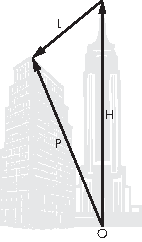

*Figure 14.1: Diagram of the initial state for the Spider-Man example*

The origin, `O`, is at the base of the Empire State Building. The vector `H` represents the position where the webbing is attached to the building, relative to `O`. The vector `P` is the position of Spider-Man relative to `O`. And `L` is the vector from the attachment point to Spider-Man.

By following the arrows from `O`, along `H`, and along `L`, we can see that

```
H + L = P
```

So we can compute `L` like this:

```
L = P - H
```

**Exercise 14.3.** As an exercise, simulate this system and estimate the parameters that maximize the distance Spider-Man swings.

1.  Implement a model of this scenario to predict Spider-Man’s trajectory.

2.  Choose the right time for Spider-Man to let go of the webbing in order to maximize the distance he travels before landing.

3.  Choose the best angle for Spider-Man to jump off the building, and the best time to let go of the webbing, to maximize range.

Use the following parameters:

-   According to the Spider-Man Wiki (<https://greenteapress.com/matlab/spider>), Spider-Man weighs 76 kg.

-   Assume his terminal velocity is 60 m/s.

-   The length of the web is 100 m.

-   The initial angle of the web is 45° to the left of straight down.

-   The spring constant of the web is 40 N/m when the cord is stretched and 0 N/m when it’s compressed.

## Celestial Mechanics

*Celestial mechanics* describes how objects move in outer space. If you did Exercise 11.2, you simulated the Earth being pulled toward the Sun in one dimension. Now we’ll simulate the Earth orbiting the Sun in two dimensions.

To keep things simple, we’ll consider only the effect of the Sun on the Earth and ignore the effect of the Earth on the Sun. So we’ll place the Sun at the origin and use a spatial vector, $\mathbf{P}$, to represent the position of the Earth relative to the Sun.

Given the mass of the Sun, $m_{1}$, and the mass of the Earth, $m_{2}$, the gravitational force between them is

$$\mathbf{F}_\mathrm{g} = -G \frac{m_1 m_2}{r^2} \hat{\mathbf{P}}$$ where $G$ is the universal gravitational constant (see <https://greenteapress.com/matlab/gravity>), $r$ is the distance of the Earth from the Sun, and $\hat{\mathbf{P}}$ is a unit vector in the direction of $\mathbf{P}$.

**Exercise 14.4.** Write a simulation of the Earth orbiting the Sun. You can look up the orbital velocity of the Earth or manually search for the initial velocity that causes the Earth to make one complete orbit in one year. Optionally, use `fminsearch` to find the velocity that gets the Earth as close as possible to the starting place after one year.

## Conservation of Energy

A useful way to check the accuracy of an ODE solver is to see whether it conserves energy. For planetary motion, it turns out that `ode45` does not.

The kinetic energy of a moving body is

$$KE = m v^2 / 2$$

The potential energy of a sun with mass $m_1$ and a planet with mass $m_2$ and a distance $r$ between them is

$$PE = -G \frac{m_1 m_2}{r}$$

**Exercise 14.5.** Write a function called `energy_func` that takes the output of your Earth simulation and computes the total energy (kinetic and potential) of the system for each estimated position and velocity.

Plot the result as a function of time and check whether it increases or decreases over the course of the simulation.

You can reduce the rate of energy loss by decreasing `ode45`’s tolerance option using `odeset` (see “ODE Events” in Section 11.3):

```
options = odeset('RelTol', 1e-5);
[T, M] = ode45(@rate_func, tspan, W, options);
```

The name of the option is `RelTol` for “relative tolerance.” The default value is `1e-3`, or 0.001. Smaller values make `ode45` less “tolerant,” so uses smaller step sizes to make the errors smaller.

Run `ode45` with a range of values for `RelTol` and confirm that as the tolerance gets smaller, the rate of energy loss decreases.

Along with `ode45`, MATLAB provides several other ODE solvers (see <https://greenteapress.com/matlab/solver>). Run your simulation with one of the other ODE solvers MATLAB provides and see if any of them conserve energy. You might find that `ode23` works surprisingly well (although technically it does not conserve energy either).

## Chapter Review

This chapter presents examples where you can apply the tools in this book to solve more realistic problems. Some of them are more serious than others, but I hope you had some fun with them.

I think this toolkit is powerful and versatile. If you use it to solve an interesting problem, let me know!

In [2]:
% Exercise 14.1 (bungee jumping): your solution here


In [3]:
% Exercise 14.2 (bungee jumping with the mass of the cord): your solution here


In [4]:
% Exercise 14.3 (Spider-Man): your solution here


In [5]:
% Exercise 14.4 (the Earth orbiting the Sun): your solution here


In [6]:
% Solution

% Calculate and plot the trajectories of two bodies with
% the given parameters, acting under the force of gravity.
% binary() animates the orbits; binary(false) plots them instead.

function binary(animate)
    if nargin < 1
        animate = true;
    end

    au = 150e9;                % astronomical unit in meters
    day = 24 * 60 * 60;        % day in seconds
    sunmass = 2.0e30;          % mass of the sun in kg

    d = 779e9;                 % initial distance in meters
    v = 13e3;                  % initial velocity in meters per second
    m1 = 2.0e30;               % mass of the sun in kg
    m2 = 1.9e27;               % mass of Jupiter
    G = 6.67e-11;              % gravitation constant in N m^2 / kg^2
    period = 4332;             % one orbit in days
    end_time = period * day;   % period in seconds

    % scaling distances
    d = d / au;
    v = v / au;
    G = G / au^3;

    % scaling times
    end_time = end_time / day;
    v = v * day;
    G = G * day^2;

    % scaling masses
    m1 = m1 / sunmass;
    m2 = m2 / sunmass;
    G = G * sunmass;

    P1 = [0;0];       % simple initial conditions
    P2 = [d;0];
    V1 = [0;0];
    V2 = [0;v];

    options = odeset('RelTol', 1e-5);
    step = end_time/period*100;
    rate = @(t, W) rate_func(t, W, G, m1, m2);
    [T, M] = ode45(rate, [0:step:end_time], [P1; P2; V1; V2], options);
    if animate
        animate_func(T,M);
    else
        plot_func(M);
    end
    energy_func(T, M, G, m1, m2);
end

function animate_func(T,M)
    % animate the positions of the planets, assuming that the
    % columns of M are x1, y1, x2, y2.
    X1 = M(:,1);
    Y1 = M(:,2);

    X2 = M(:,3);
    Y2 = M(:,4);

    minmax = [min([X1;X2]), max([X1;X2]), min([Y1;Y2]), max([Y1;Y2])];

    for i=1:length(T)
        clf;
        hold on;
        axis(minmax);
        draw_func(X1(i), Y1(i), X2(i), Y2(i));
        drawnow;
        if i < length(T)
            dt = T(i+1) - T(i);
            speedup = 1000;
            pause(dt/speedup);
        end
    end
    hold off
    figure
end

function plot_func(M)
    % plot the orbits; the columns of M are x1, y1, x2, y2.
    plot(M(:,1), M(:,2), 'r.', M(:,3), M(:,4), 'b-')
    axis equal
    figure
end

function energy_func(T, M, G, m1, m2)
    for i=1:length(T)
        P1 = M(i,1:2);
        P2 = M(i,3:4);
        pe = potential_func(P1, P2, G, m1, m2);
        V1 = M(i,5:6);
        V2 = M(i,7:8);
        ke = kinetic_func(V1, m1) + kinetic_func(V2, m2);
        E(i) = ke + pe;
    end
    plot(T, E);
    loss = (E(1) - E(end)) / E(1)
end

function res = potential_func(P1, P2, G, m1, m2)
    r = norm(P1-P2);
    pe = -G * m1 * m2 / r;
    res = pe;
end

function res = kinetic_func(V, m)
    v = norm(V);
    ke = m * v^2 / 2;
    res = ke;
end

function draw_func(x1, y1, x2, y2)
    plot(x1, y1, 'r.', 'MarkerSize', 50);
    plot(x2, y2, 'b.', 'MarkerSize', 20);
end

function res = rate_func(t, W, G, m1, m2)
    % this is a slope function invoked by ode45
    n = length(W)/2;
    P = W(1:n);
    V = W(n+1:end);

    dRdt = V;
    dVdt = acceleration_func(t, P, V, G, m1, m2);

    res = [dRdt; dVdt];
end

function res = acceleration_func(t, P, V, G, m1, m2)
    % compute acceleration due to gravity
    P1 = P(1:2);
    P2 = P(3:4);

    F12 = gravity_force_func(P1, P2, m1, m2, G);

    A1 = F12 / m1;
    A2 = -F12 / m2;
    res = [A1; A2];
end

function Fg = gravity_force_func(P1, P2, m1, m2, G)
    % compute the force of gravity acting on a body at
    % P1 with mass m1, due to a body at P2 with mass m2
    R = P2 - P1;
    r = norm(R);
    Rhat = R/r;

    Fg = G * m1 * m2 / r^2 * Rhat;
end

loss = -1.8505e-05


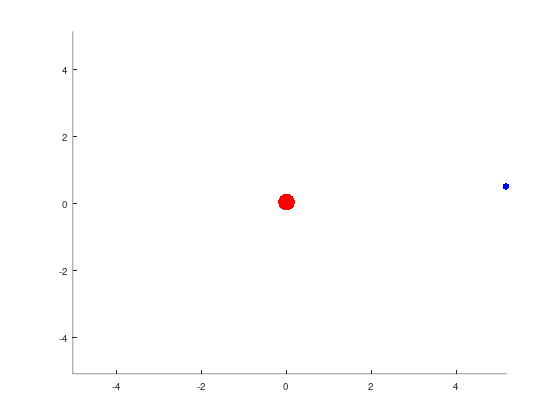

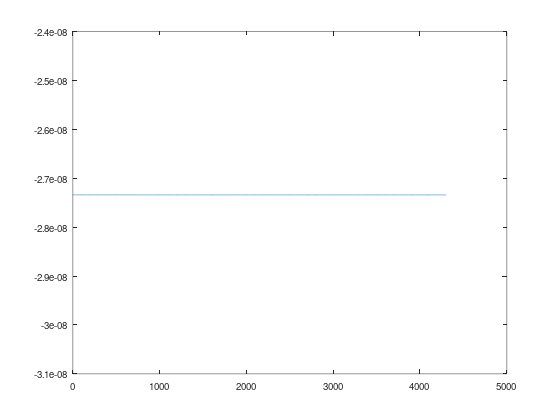

In [7]:
% Solution

binary()    % the Sun and Jupiter; binary(false) plots the orbits instead